In [1]:
pip install mlflow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 2.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 3.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 27.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 31.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 38.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 9.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1

In [2]:
import mlflow
import mlflow.sklearn

import pandas as pd

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score
from sklearn.metrics import roc_auc_score

In [3]:
data = load_breast_cancer()

X = data.data
y = data.target


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [4]:
mlflow.set_experiment(
    "Breast Cancer Classification"
)

2026/10/10 07:25:14 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/10 07:25:14 INFO mlflow.store.db.utils: Updating database tables
2026/10/10 07:25:21 INFO mlflow.tracking.fluent: Experiment with name 'Breast Cancer Classification' does not exist. Creating a new experiment.


<Experiment: artifact_location='/content/mlruns/1', creation_time=1791617121100, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1791617121100, lifecycle_stage='active', name='Breast Cancer Classification', tags={}, trace_location=None, workspace='default'>

In [5]:
params = {
    "n_estimators":100,
    "max_depth":5,
    "random_state":42
}


with mlflow.start_run(
    run_name="RandomForest_baseline"
):

    model = RandomForestClassifier(
        **params
    )

    model.fit(
        X_train,
        y_train
    )


    prediction = model.predict(
        X_test
    )


    accuracy = accuracy_score(
        y_test,
        prediction
    )


    f1 = f1_score(
        y_test,
        prediction
    )


    mlflow.log_params(
        params
    )


    mlflow.log_metric(
        "accuracy",
        accuracy
    )


    mlflow.log_metric(
        "f1_score",
        f1
    )


    mlflow.sklearn.log_model(
        model,
        "random_forest_model",
        skops_trusted_types=["sklearn.tree._tree.Tree"]
    )

2026/10/10 07:25:48 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


In [6]:
params = {
    "n_estimators":200,
    "max_depth":10,
    "random_state":42
}


with mlflow.start_run(
    run_name="RandomForest_tuning"
):

    model = RandomForestClassifier(
        **params
    )

    model.fit(
        X_train,
        y_train
    )


    prediction = model.predict(
        X_test
    )


    accuracy = accuracy_score(
        y_test,
        prediction
    )


    f1 = f1_score(
        y_test,
        prediction
    )


    mlflow.log_params(
        params
    )


    mlflow.log_metric(
        "accuracy",
        accuracy
    )


    mlflow.log_metric(
        "f1_score",
        f1
    )


    mlflow.sklearn.log_model(
        model,
        "random_forest_tuned",
        skops_trusted_types=["sklearn.tree._tree.Tree"]
    )

2026/10/10 07:26:50 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


In [7]:
runs = mlflow.search_runs()

runs[
[
"run_id",
"params.n_estimators",
"params.max_depth",
"metrics.accuracy",
"metrics.f1_score"
]
]

,run_id,params.n_estimators,params.max_depth,metrics.accuracy,metrics.f1_score
0,cf58209932cd4239b50ca590add9bae7,200,10,0.964912,0.972222
1,0805a40247934f57b0119aae2f009b8d,100,5,0.964912,0.972222


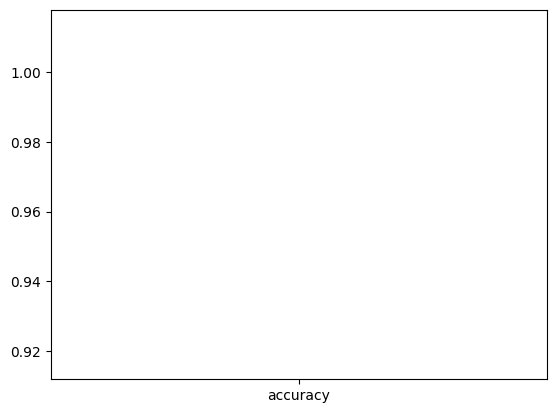

In [8]:
import matplotlib.pyplot as plt

plt.plot(
    ["accuracy"],
    [accuracy]
)

plt.savefig(
    "accuracy_plot.png"
)


mlflow.log_artifact(
    "accuracy_plot.png"
)